# 聚合物温度模拟笔记本

本笔记本演示两件事：
1. 用 **Fox 方程** 估算共聚物的玻璃化转变温度 Tg；
2. 模拟放热聚合反应中 **反应器温度随时间的变化**（含夹套冷却）。

模型要点：
- 反应速率遵循 Arrhenius 方程 $k(T)=A\,e^{-E_a/RT}$
- 转化率 $dX/dt = k(T)(1-X)$
- 能量平衡 $m C_p\, dT/dt = (-\Delta H)\, m\, dX/dt - UA(T-T_{cool})$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('numpy', np.__version__, '| matplotlib', plt.matplotlib.__version__)

numpy 2.5.1 | matplotlib 3.11.1


## 1. 共聚物玻璃化转变温度 Tg —— Fox 方程

$$\frac{1}{T_g} = \frac{w_1}{T_{g1}} + \frac{w_2}{T_{g2}}$$

以苯乙烯/丁二烯共聚物为例。

In [2]:
def fox_tg(w1, tg1, w2, tg2):
    """Fox 方程计算共聚物 Tg (K)。"""
    return 1.0 / (w1 / tg1 + w2 / tg2)

tg_styrene = 378.0     # PS 的 Tg (K) ≈ 105 °C
tg_butadiene = 178.0   # PB 的 Tg (K) ≈ -95 °C
w_s, w_b = 0.7, 0.3

Tg = fox_tg(w_s, tg_styrene, w_b, tg_butadiene)
print(f'共聚物 Tg ≈ {Tg:.2f} K  ({Tg - 273.15:.2f} °C)')

共聚物 Tg ≈ 282.71 K  (9.56 °C)


## 2. 反应器温度模拟

用欧拉积分求解转化率与温度的常微分方程组。

In [3]:
def simulate_polymerization(
    T0=320.0, monomer_mass=1.0, Cp=1.8, dH=-80.0,
    A=3.0e8, Ea=60.0, U_A=0.02, T_cool=300.0,
    t_end=600.0, dt=0.2,
):
    R = 8.314e-3  # kJ/(mol·K)
    n = int(t_end / dt)
    t = np.zeros(n + 1); T = np.zeros(n + 1); X = np.zeros(n + 1)
    T[0] = T0; X[0] = 0.0
    for i in range(n):
        k = A * np.exp(-Ea / (R * T[i]))
        dXdt = k * (1.0 - X[i])
        Q_rxn = -dH * monomer_mass * dXdt
        Q_cool = U_A * (T[i] - T_cool)
        dTdt = (Q_rxn - Q_cool) / (monomer_mass * Cp)
        t[i+1] = t[i] + dt
        X[i+1] = X[i] + dXdt * dt
        T[i+1] = T[i] + dTdt * dt
    return t, T, X

In [4]:
t, T, X = simulate_polymerization()
print(f'初始温度 T0   = {T[0]:.2f} K')
print(f'最高温度 Tmax = {T.max():.2f} K  (温升 {T.max() - T[0]:.2f} K)')
print(f'最终温度      = {T[-1]:.2f} K')
print(f'最终转化率    = {X[-1]:.4f}')
if T.max() >= Tg:
    print(f'⚠ 放热峰 {T.max():.1f} K 超过 Tg {Tg:.1f} K，注意凝胶效应（Trommsdorff 自动加速）。')

初始温度 T0   = 320.00 K
最高温度 Tmax = 356.54 K  (温升 36.54 K)
最终温度      = 300.09 K
最终转化率    = 1.0000
⚠ 放热峰 356.5 K 超过 Tg 282.7 K，注意凝胶效应（Trommsdorff 自动加速）。


## 3. 可视化

温度（左轴）与转化率（右轴）随时间变化，并标出 Tg 参考线。

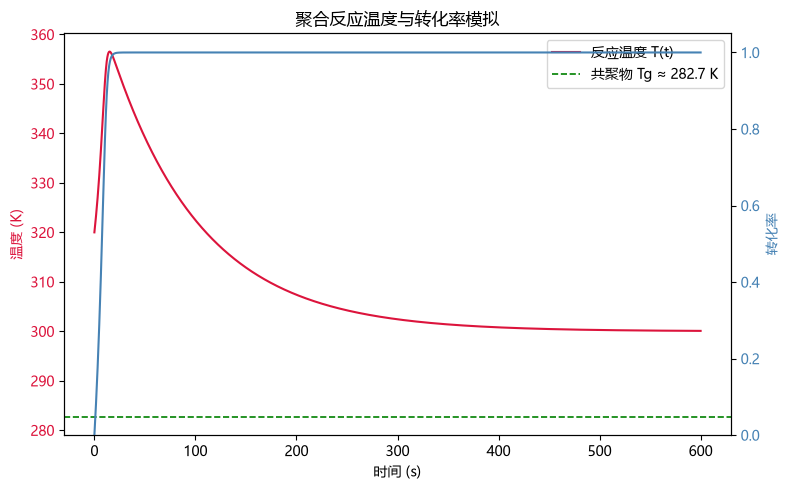

In [5]:
fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(t, T, color='crimson', label='反应温度 T(t)')
ax1.set_xlabel('时间 (s)'); ax1.set_ylabel('温度 (K)', color='crimson')
ax1.tick_params(axis='y', labelcolor='crimson')
ax1.axhline(Tg, color='green', ls='--', lw=1.2, label=f'共聚物 Tg ≈ {Tg:.1f} K')

ax2 = ax1.twinx()
ax2.plot(t, X, color='steelblue', label='转化率 X(t)')
ax2.set_ylabel('转化率', color='steelblue')
ax2.tick_params(axis='y', labelcolor='steelblue')
ax2.set_ylim(0, 1.05)

ax1.legend(loc='upper right')
plt.title('聚合反应温度与转化率模拟')
fig.tight_layout()
plt.show()

## 小结

- Fox 方程快速估算共聚物 Tg，质量分数对 Tg 影响显著。
- 放热聚合若冷却不足，温度会迅速飙升并可能越过 Tg，引发凝胶效应。
- 调节 `U_A`（冷却强度）、`T_cool`、`Ea` 可观察不同温升曲线。